# 🔬 Artículo Q1/Q2: Fusión Multimodal con Atención Cruzada, Predicción Conforme y Validación Externa Multicéntrica en Triaje de Cáncer de Piel
**Título tentativo del manuscrito:**  
> *Uncertainty-Aware Cross-Modal Attention Fusion for Smartphone-Based Skin Cancer Triage: A Cross-Continental External Validation and Fairness Study on ISIC 2024 and PAD-UFES-20*

**Optimizado para:** Google Colab Pro / Pro+ (NVIDIA L4 24GB / A100 40GB-80GB con `bfloat16` AMP)  
**Revistas Objetivo (Q1/Q2):** *Computers in Biology and Medicine*, *Computer Methods and Programs in Biomedicine*, *Biomedical Signal Processing and Control*, *IEEE JBHI*, *Scientific Reports*.

---

### 📋 Estructura Experimental (Estándar de Revisión por Pares Q1)
1. **Celda 1 — Entorno y Reproducibilidad Estrica:** Instalación de librerías (`timm`, `albumentations`, `h5py`, `scikit-learn`), detección de GPU L4/A100 (`bfloat16`) y fijación de semillas globales.
2. **Celda 2 — Descarga Automatizada de Cohorte Primaria (`ISIC 2024 SLICE-3D`) y Cohorte Externa (`PAD-UFES-20`):** Lectura ultra-rápida desde `train-image.hdf5` (~2.5 GB) sin saturar el disco de Colab, y descarga directa de `PAD-UFES-20` desde Mendeley/Kaggle.
3. **Celda 3 — Armonización Clínica Cross-Continental (Preprocesamiento Tabular + Imagen):** Alineación de variables clínicas entre Norteamérica/Europa/Oceanía (`ISIC 2024`) y Latinoamérica (`PAD-UFES-20`: edad, sexo, región anatómica estandarizada y diámetro en mm) + preservación del fototipo *Fitzpatrick (I–VI)* para auditoría de equidad (*Fairness*).
4. **Celda 4 — Validación Cruzada Estratificada por Paciente (`StratifiedGroupKFold`):** Evita el *data leakage* asegurando que ningún paciente comparta lesiones entre `train` y `val`, más submuestreo dinámico balanceado por época para manejar el desbalance extremo (1:1000).
5. **Celda 5 — Arquitecturas y Estudio de Ablación (3 Paradigmas):**
   - **Modelo A (Baseline Unimodal):** Solo imagen (`ConvNeXt-Small` / `EVA-02` / `Swin-Small`).
   - **Modelo B (Late Concatenation Fusion):** Concatenación tardía de embeddings visuales y tabulares.
   - **Modelo C (Propuesto — Cross-Modal FiLM & Gated Attention Fusion - CM-GAF):** Modulación espacial y de canal guiada por el contexto clínico del paciente.
6. **Celda 6 — Entrenamiento con Precisión Mixta (`bfloat16`), Focal + Cosine Loss:** Loop de entrenamiento acelerado para GPU L4/A100.
7. **Celda 7 — Métricas Clínicas Q1 + Intervalos de Confianza Bootstrap (95% CI) + Test de DeLong:** Cálculo de `ROC-AUC`, `PR-AUC`, **`pAUC@80%TPR`** (métrica oficial de triaje clínico por encima del 80% de sensibilidad), `Brier Score` y `ECE` (Expected Calibration Error).
8. **Celda 8 — Triaje Clínico con Garantías Matemáticas (*Split Conformal Prediction*):** Control estadístico de falsos negativos ($\alpha = 0.05 \Rightarrow \text{Sensibilidad} \ge 95\%$) clasificando cada lesión en: *Descartar (Benigno)*, *Zona Gris (Derivar a Dermatoscopía)* o *Biopsia Urgente (Maligno)*.
9. **Celda 9 — Validación Externa (*Zero-Shot* vs *Test-Time Adaptation - TTA*) y Auditoría de Equidad (*Fairness* por Fototipo Fitzpatrick I–VI):** Evaluación en `PAD-UFES-20` (Brasil) y generación de las Figuras y Tablas en formato LaTeX listas para el paper.


In [1]:
# ==============================================================================
# CELDA 1: INSTALACIÓN DE DEPENDENCIAS, HARDWARE CHECK (L4/A100/MPS) Y SEMILLAS
# ==============================================================================
import os
import sys
import shutil
import subprocess
if "google.colab" in sys.modules:
    os.system("pip install -q 'timm>=1.0.9' 'albumentations>=1.4.10' 'kaggle>=1.6.17' kagglehub h5py scikit-learn scipy statsmodels tqdm matplotlib seaborn pandas")

import io
import gc
import math
import json
import random
import zipfile
import urllib.request
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import h5py
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve,
    brier_score_loss, confusion_matrix
)
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True  # Acelera convoluciones en L4 / A100

seed_everything(42)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

AMP_DTYPE = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16

print(f"Dispositivo activo: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f"VRAM Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"Precisión Mixta Automática (AMP): {AMP_DTYPE}")


Dispositivo activo: cuda
GPU detectada: NVIDIA L4
VRAM Total: 23.66 GB
Precisión Mixta Automática (AMP): torch.bfloat16


### 📥 Celda 2: Descarga de Cohorte Primaria (`ISIC 2024`) y Cohorte Externa (`PAD-UFES-20`)
- Para **ISIC 2024**, usamos la API oficial de Kaggle. Si aún no has subido tu `kaggle.json`, la celda te permite subirlo o configurar tus credenciales. Solo necesitas `train-metadata.csv` y `train-image.hdf5` (~2.5 GB), que se lee directamente desde disco sin descomprimir 400,000 archivos individuales.
- Para **PAD-UFES-20** (cohorte externa en Brasil con fotos de smartphone y fototipo Fitzpatrick), se descarga directamente desde el repositorio oficial de Mendeley Data / Kaggle (~2 GB).
- **Modo Demo / Verificación Rápida (`USE_SYNTHETIC_IF_MISSING = True`):** Si ejecutas la celda antes de configurar tu token de Kaggle, generará automáticamente un dataset sintético con el esquema exacto de `ISIC 2024` y `PAD-UFES-20` para que puedas probar todo el pipeline de principio a fin sin errores.


In [2]:
# ==============================================================================
# CELDA 2: CONFIGURACIÓN DE CREDENCIALES KAGGLE, DIRECTORIOS Y DESCARGA OFICIAL
# ==============================================================================
# Configuración automática de tu Kaggle Access Token (API v2)
KAGGLE_ACCESS_TOKEN = "KGAT_d38ca0073abd32a7711f6bfe176722a5"
os.environ["KAGGLE_API_TOKEN"] = KAGGLE_ACCESS_TOKEN

def setup_kaggle_credentials(token: str = KAGGLE_ACCESS_TOKEN) -> Path:
    kaggle_dir = Path.home() / ".kaggle"
    token_file = kaggle_dir / "access_token"
    try:
        kaggle_dir.mkdir(parents=True, exist_ok=True)
        token_file.write_text(token.strip() + "\n", encoding="utf-8")
        os.chmod(token_file, 0o600)
        print(f"🔑 Token de Kaggle configurado en: {token_file} (permisos 600)")
    except PermissionError:
        print(f"ℹ️ Usando token de Kaggle desde memoria/entorno (KAGGLE_API_TOKEN activo).")
    return token_file

setup_kaggle_credentials()

_BASE_ROOT = Path("/content") if (Path("/content").exists() and os.access("/content", os.W_OK)) else Path("./workspace_q1")
DATA_ROOT = _BASE_ROOT / "data_q1_derma"
ISIC_DIR = DATA_ROOT / "isic_2024"
PAD_DIR = DATA_ROOT / "pad_ufes_20"
OUTPUT_DIR = _BASE_ROOT / "outputs_q1_paper"

for d in [ISIC_DIR, PAD_DIR, OUTPUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Si aún no has aceptado las reglas de ISIC 2024 en la web de Kaggle o ejecutas sin red, usa el fallback
USE_SYNTHETIC_IF_MISSING = True

def download_isic_2024() -> bool:
    hdf5_path = ISIC_DIR / "train-image.hdf5"
    meta_path = ISIC_DIR / "train-metadata.csv"
    if hdf5_path.exists() and meta_path.exists():
        print("✅ ISIC 2024 ya está disponible en:", ISIC_DIR)
        return True
    kaggle_bin = shutil.which("kaggle")
    if kaggle_bin is None:
        print("⚠️ CLI 'kaggle' no instalado en este entorno local (en Colab se instala en Celda 1).")
        return False
    print("⬇️ Descargando train-metadata.csv y train-image.hdf5 de ISIC 2024 desde Kaggle...")
    r1 = subprocess.run([kaggle_bin, "competitions", "download", "-c", "isic-2024-challenge", "-f", "train-metadata.csv", "-p", str(ISIC_DIR)], capture_output=True, text=True)
    r2 = subprocess.run([kaggle_bin, "competitions", "download", "-c", "isic-2024-challenge", "-f", "train-image.hdf5", "-p", str(ISIC_DIR)], capture_output=True, text=True)
    if r1.returncode != 0 or r2.returncode != 0:
        print("⚠️ Aviso de Kaggle API:", (r1.stderr or r1.stdout or r2.stderr or r2.stdout).strip())
        print("👉 Asegúrate de haber aceptado las reglas del reto en: https://www.kaggle.com/competitions/isic-2024-challenge/rules")
        return False
    for zf in ISIC_DIR.glob("*.zip"):
        with zipfile.ZipFile(zf, 'r') as z:
            z.extractall(ISIC_DIR)
        zf.unlink()
    return hdf5_path.exists() and meta_path.exists()

def download_pad_ufes_20() -> bool:
    meta_path = PAD_DIR / "metadata.csv"
    img_dir = PAD_DIR / "images"
    if meta_path.exists() and img_dir.exists() and any(img_dir.iterdir()):
        print("✅ PAD-UFES-20 ya está disponible en:", PAD_DIR)
        return True
    kaggle_bin = shutil.which("kaggle")
    if kaggle_bin is None:
        return False
    print("⬇️ Descargando cohorte externa PAD-UFES-20 desde Kaggle (mahdavi1202/skin-cancer)...")
    r = subprocess.run([kaggle_bin, "datasets", "download", "-d", "mahdavi1202/skin-cancer", "-p", str(PAD_DIR), "--unzip"], capture_output=True, text=True)
    if r.returncode != 0:
        print("⚠️ No se pudo descargar PAD-UFES-20 desde Kaggle:", (r.stderr or r.stdout).strip())
        return False
    img_dir.mkdir(exist_ok=True)
    for p in PAD_DIR.rglob("*.png"):
        if p.parent != img_dir:
            shutil.move(str(p), str(img_dir / p.name))
    return meta_path.exists()

def _synthesize_lesion_rgb(rng, y: int, age: float, diam: float, site: str, fitz: int = 2, size: int = 96) -> np.ndarray:
    """Genera una imagen dermatológica sintética con estructura espacial realista
    (tono de piel basal según fototipo, lesión central pigmentada e interacción clínica)."""
    yy, xx = np.mgrid[-1.0:1.0:complex(0, size), -1.0:1.0:complex(0, size)]
    r = np.sqrt(xx**2 + yy**2)
    # Tono de piel base según Fitzpatrick (I a VI)
    skin_base = max(95, 225 - 20 * (fitz - 1))
    bg = rng.normal(skin_base, 8.0, size=(size, size, 3))
    # Radio y asimetría de la lesión
    radius = np.clip(0.28 + 0.012 * diam + (0.08 if y == 1 else 0.0), 0.22, 0.78)
    angle = np.arctan2(yy, xx)
    asym = 0.09 * np.sin(3 * angle) if y == 1 else 0.02 * np.sin(2 * angle)
    mask = np.clip(1.0 - (r / (radius + asym))**2, 0.0, 1.0)[..., None]
    # Coloración diferencial e interacción cruzada con edad/sitio
    darkening = (52.0 if y == 1 else 26.0) + (12.0 if (y == 1 and age > 60) else 0.0)
    red_shift = 22.0 if (y == 1 and site in ["head/neck", "FACE", "NECK"]) else 5.0
    lesion_rgb = np.zeros((size, size, 3), dtype=np.float32)
    lesion_rgb[..., 0] = -darkening + red_shift
    lesion_rgb[..., 1] = -darkening * 1.15
    lesion_rgb[..., 2] = -darkening * 1.25
    img = np.clip(bg + mask * lesion_rgb + rng.normal(0, 5.0, size=(size, size, 3)), 0, 255).astype(np.uint8)
    return img

def create_synthetic_fallback_datasets(n_isic: int = 1200, n_pad: int = 400):
    """Crea archivos HDF5 y CSV con el esquema exacto de ISIC 2024 y PAD-UFES-20
    para verificar el pipeline completo si aún no se han descargado los gigabytes reales."""
    print("🧪 Generando cohorte de prueba con esquema exacto (ISIC 2024 + PAD-UFES-20)...")
    rng = np.random.default_rng(42)

    # 1. ISIC 2024 schema
    isic_ids = [f"ISIC_{1000000 + i}" for i in range(n_isic)]
    patient_ids = [f"PAT_ISIC_{i // 5}" for i in range(n_isic)]
    targets = (rng.random(n_isic) < 0.12).astype(int)
    ages = np.clip(rng.normal(54 + 15 * targets, 13, n_isic), 18, 90).round(0)
    sexes = rng.choice(["male", "female"], size=n_isic, p=[0.54, 0.46])
    sites = [
        rng.choice(["head/neck", "posterior torso", "upper extremity"], p=[0.50, 0.30, 0.20]) if t == 1
        else rng.choice(["anterior torso", "posterior torso", "lower extremity", "upper extremity", "head/neck"])
        for t in targets
    ]
    diams = np.clip(rng.lognormal(1.55 + 0.50 * targets, 0.38, n_isic), 1.5, 45.0).round(2)

    df_isic = pd.DataFrame({
        "isic_id": isic_ids,
        "patient_id": patient_ids,
        "target": targets,
        "age_approx": ages,
        "sex": sexes,
        "anatom_site_general": sites,
        "clin_size_long_diam_mm": diams,
    })
    df_isic.to_csv(ISIC_DIR / "train-metadata.csv", index=False)

    with h5py.File(ISIC_DIR / "train-image.hdf5", "w") as hf:
        for iid, y, a, d, s in zip(isic_ids, targets, ages, diams, sites):
            arr = _synthesize_lesion_rgb(rng, int(y), float(a), float(d), str(s), fitz=int(rng.choice([1, 2, 3])))
            img = Image.fromarray(arr)
            buf = io.BytesIO()
            img.save(buf, format="JPEG", quality=90)
            hf.create_dataset(iid, data=np.void(buf.getvalue()))

    # 2. PAD-UFES-20 schema (Cohorte Externa Latinoamericana con Fototipo Fitzpatrick)
    pad_ids = [f"PAD_{20000 + i}.png" for i in range(n_pad)]
    pad_pats = [f"PAT_PAD_{i // 3}" for i in range(n_pad)]
    pad_mal = (rng.random(n_pad) < 0.25).astype(int)
    pad_diag = [rng.choice(["BCC", "MEL", "SCC"]) if m == 1 else rng.choice(["ACK", "NEV", "SEK"]) for m in pad_mal]
    pad_ages = np.clip(rng.normal(56 + 15 * pad_mal, 14, n_pad), 18, 92).round(0)
    pad_gender = rng.choice(["MALE", "FEMALE"], size=n_pad)
    pad_region = [
        rng.choice(["FACE", "NECK", "BACK", "FOREARM"], p=[0.48, 0.22, 0.18, 0.12]) if m == 1
        else rng.choice(["FACE", "CHEST", "BACK", "ARM", "FOREARM", "THIGH", "NECK"])
        for m in pad_mal
    ]
    pad_d1 = np.clip(rng.lognormal(1.65 + 0.50 * pad_mal, 0.40, n_pad), 2.0, 50.0).round(1)
    pad_fitz = rng.choice([1, 2, 3, 4, 5, 6], size=n_pad, p=[0.12, 0.30, 0.28, 0.16, 0.08, 0.06])

    df_pad = pd.DataFrame({
        "img_id": pad_ids,
        "patient_id": pad_pats,
        "diagnostic": pad_diag,
        "age": pad_ages,
        "gender": pad_gender,
        "region": pad_region,
        "diameter_1": pad_d1,
        "fitspatrick": pad_fitz,
        "biopsed": True
    })
    df_pad.to_csv(PAD_DIR / "metadata.csv", index=False)

    pad_img_dir = PAD_DIR / "images"
    pad_img_dir.mkdir(exist_ok=True)
    for pid, m, a, d, r_site, fz in zip(pad_ids, pad_mal, pad_ages, pad_d1, pad_region, pad_fitz):
        arr = _synthesize_lesion_rgb(rng, int(m), float(a), float(d), str(r_site), fitz=int(fz))
        Image.fromarray(arr).save(pad_img_dir / pid)
    print("✅ Datasets de verificación listos en:", DATA_ROOT)

has_real_isic = download_isic_2024()
has_real_pad = download_pad_ufes_20()
if (not has_real_isic or not has_real_pad) and USE_SYNTHETIC_IF_MISSING:
    create_synthetic_fallback_datasets()


🔑 Token de Kaggle configurado en: /root/.kaggle/access_token (permisos 600)
⬇️ Descargando train-metadata.csv y train-image.hdf5 de ISIC 2024 desde Kaggle...
⬇️ Descargando cohorte externa PAD-UFES-20 desde Kaggle (mahdavi1202/skin-cancer)...


### 🔄 Celda 3: Armonización Clínica Cross-Continental (`ISIC 2024` ↔ `PAD-UFES-20`)
Para que un artículo de validación externa sea aceptado en una revista **Q1**, las variables clínicas de entrada deben mapearse a una ontología clínica común entre el conjunto de entrenamiento (`ISIC 2024`) y el conjunto externo (`PAD-UFES-20`):
- **Edad (`age_years`):** Numérica continua, imputada con la mediana del conjunto de entrenamiento.
- **Diámetro máximo de la lesión (`diameter_mm`):** Numérica continua (`clin_size_long_diam_mm` en ISIC ↔ `diameter_1` en PAD-UFES-20).
- **Sexo biológico (`sex_ harmonized`):** `male`, `female`, `unknown`.
- **Sitio anatómico (`anatom_site_harmonized`):** Mapeo ontológico de las 14 regiones de `PAD-UFES-20` (`FACE`, `SCALP`, `NECK`, `ARM`, `CHEST`, `BACK`, `THIGH`, etc.) a las 5 macro-regiones de `ISIC 2024` (`head/neck`, `upper extremity`, `lower extremity`, `anterior torso`, `posterior torso`).
- **Etiqueta diagnóstica (`target`):** `1` para lesiones malignas confirmadas por biopsia (`MEL`, `BCC`, `SCC` en PAD-UFES-20; `target=1` en ISIC 2024) y `0` para lesiones benignas.


In [3]:
# ==============================================================================
# CELDA 3: ARMONIZACIÓN DE METADATOS CLÍNICOS ENTRE COHORTES
# ==============================================================================
PAD_REGION_TO_ISIC_SITE = {
    "FACE": "head/neck", "SCALP": "head/neck", "NOSE": "head/neck",
    "EAR": "head/neck", "LIP": "head/neck", "NECK": "head/neck",
    "CHEST": "anterior torso", "ABDOMEN": "anterior torso",
    "BACK": "posterior torso",
    "ARM": "upper extremity", "FOREARM": "upper extremity", "HAND": "upper extremity",
    "THIGH": "lower extremity", "SHIN": "lower extremity", "FOOT": "lower extremity"
}

def load_and_harmonize_isic(meta_csv: Path) -> pd.DataFrame:
    df = pd.read_csv(meta_csv, low_memory=False)
    out = pd.DataFrame()
    out["sample_id"] = df["isic_id"].astype(str)
    out["patient_id"] = df["patient_id"].fillna(df["isic_id"]).astype(str)
    out["target"] = df["target"].astype(int)
    out["age_years"] = pd.to_numeric(df.get("age_approx", np.nan), errors="coerce")
    out["diameter_mm"] = pd.to_numeric(df.get("clin_size_long_diam_mm", np.nan), errors="coerce")
    out["sex_clean"] = (
        df.get("sex", pd.Series(["unknown"] * len(df)))
        .fillna("unknown").astype(str).str.strip().str.lower()
    )
    out.loc[~out["sex_clean"].isin(["male", "female"]), "sex_clean"] = "unknown"

    site = (
        df.get("anatom_site_general", pd.Series(["unknown"] * len(df)))
        .fillna("unknown").astype(str).str.strip().str.lower()
    )
    valid_sites = ["head/neck", "upper extremity", "lower extremity", "anterior torso", "posterior torso"]
    out["site_clean"] = np.where(site.isin(valid_sites), site, "unknown")
    out["fitzpatrick"] = np.nan  # No reportado en ISIC 2024
    out["cohort"] = "ISIC_2024"
    return out

def load_and_harmonize_pad(meta_csv: Path) -> pd.DataFrame:
    df = pd.read_csv(meta_csv, low_memory=False)
    out = pd.DataFrame()
    out["sample_id"] = df["img_id"].astype(str)
    out["patient_id"] = df["patient_id"].fillna(df["img_id"]).astype(str)
    # Malignas: Melanoma (MEL), Carcinoma Basocelular (BCC), Carcinoma Escamocelular (SCC)
    out["target"] = df["diagnostic"].astype(str).str.upper().isin(["MEL", "BCC", "SCC"]).astype(int)
    out["diagnostic_raw"] = df["diagnostic"].astype(str).str.upper()
    out["age_years"] = pd.to_numeric(df.get("age", np.nan), errors="coerce")
    out["diameter_mm"] = pd.to_numeric(df.get("diameter_1", np.nan), errors="coerce")

    sex = df.get("gender", pd.Series(["unknown"] * len(df))).fillna("unknown").astype(str).str.strip().str.lower()
    out["sex_clean"] = np.where(sex.isin(["male", "female"]), sex, "unknown")

    raw_reg = df.get("region", pd.Series(["UNKNOWN"] * len(df))).fillna("UNKNOWN").astype(str).str.strip().str.upper()
    out["site_clean"] = raw_reg.map(PAD_REGION_TO_ISIC_SITE).fillna("unknown")
    out["fitzpatrick"] = pd.to_numeric(df.get("fitspatrick", np.nan), errors="coerce")
    out["cohort"] = "PAD_UFES_20"
    return out

df_isic = load_and_harmonize_isic(ISIC_DIR / "train-metadata.csv")
df_pad = load_and_harmonize_pad(PAD_DIR / "metadata.csv")

print(f"📊 Cohorte Primaria (ISIC 2024): {len(df_isic):,} lesiones | Malignas: {df_isic['target'].sum():,} ({df_isic['target'].mean()*100:.2f}%)")
print(f"🌎 Cohorte Externa (PAD-UFES-20): {len(df_pad):,} lesiones | Malignas: {df_pad['target'].sum():,} ({df_pad['target'].mean()*100:.2f}%)")
display(df_isic.head(3))
display(df_pad.head(3))


📊 Cohorte Primaria (ISIC 2024): 401,059 lesiones | Malignas: 393 (0.10%)
🌎 Cohorte Externa (PAD-UFES-20): 2,298 lesiones | Malignas: 1,089 (47.39%)


,sample_id,patient_id,target,age_years,diameter_mm,sex_clean,site_clean,fitzpatrick,cohort
0,ISIC_0015670,IP_1235828,0,60.0,3.04,male,lower extremity,NaN,ISIC_2024
1,ISIC_0015845,IP_8170065,0,60.0,1.10,male,head/neck,NaN,ISIC_2024
2,ISIC_0015864,IP_6724798,0,60.0,3.40,male,posterior torso,NaN,ISIC_2024


,sample_id,patient_id,target,diagnostic_raw,age_years,diameter_mm,sex_clean,site_clean,fitzpatrick,cohort
0,PAT_1516_1765_530.png,PAT_1516,0,NEV,8,NaN,unknown,upper extremity,NaN,PAD_UFES_20
1,PAT_46_881_939.png,PAT_46,1,BCC,55,6.0,female,head/neck,3.0,PAD_UFES_20
2,PAT_1545_1867_547.png,PAT_1545,0,ACK,77,NaN,unknown,head/neck,NaN,PAD_UFES_20


### 🧬 Celda 4: Preprocesador Tabular Sin Fuga de Datos (*Zero Data Leakage*) y `Dataset` Multimodal Híbrido
- Ajustamos el `StandardScaler` y el `OneHotEncoder` **exclusivamente en el particionado de entrenamiento (`train`) de ISIC 2024** y aplicamos esa misma transformación a validación, calibración conforme y a la cohorte externa `PAD-UFES-20`.
- Implementamos **muestreo balanceado inteligente por época** para que en cada época en Colab Pro el modelo vea **todos los casos malignos (`target=1`)** y una proporción controlada de benignos (`neg_to_pos_ratio = 15`), permitiendo entrenar épocas en **segundos** sobre la GPU L4/A100 sin perder diversidad.


In [4]:
# ==============================================================================
# CELDA 4: PREPROCESADOR TABULAR, PARTICIÓN POR PACIENTE Y DATASET MULTIMODAL
# ==============================================================================
class ClinicalTabularPreprocessor:
    def __init__(self):
        self.num_cols = ["age_years", "diameter_mm"]
        self.cat_cols = ["sex_clean", "site_clean"]
        self.num_medians = {}
        self.scaler = StandardScaler()
        self.ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        self.feature_names = []

    def fit(self, df: pd.DataFrame):
        df_num = df[self.num_cols].copy()
        for col in self.num_cols:
            med = float(df_num[col].median()) if not df_num[col].isna().all() else 50.0
            self.num_medians[col] = med
            df_num[col] = df_num[col].fillna(med)
        self.scaler.fit(df_num.values)
        self.ohe.fit(df[self.cat_cols].fillna("unknown").values)
        self.feature_names = (
            self.num_cols +
            [f"{col}_missing" for col in self.num_cols] +
            list(self.ohe.get_feature_names_out(self.cat_cols))
        )
        return self

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        df_num = df[self.num_cols].copy()
        missing_flags = np.column_stack([df_num[col].isna().astype(np.float32) for col in self.num_cols])
        for col in self.num_cols:
            df_num[col] = df_num[col].fillna(self.num_medians[col])
        scaled_num = self.scaler.transform(df_num.values).astype(np.float32)
        cat_encoded = self.ohe.transform(df[self.cat_cols].fillna("unknown").values).astype(np.float32)
        return np.hstack([scaled_num, missing_flags, cat_encoded]).astype(np.float32)

# Partición agrupada por paciente (5 folds): 3 folds Train, 1 fold Calibración Conforme, 1 fold Test Interno
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
df_isic["fold"] = -1
for fold_idx, (_, val_idx) in enumerate(sgkf.split(df_isic, df_isic["target"], df_isic["patient_id"])):
    df_isic.loc[val_idx, "fold"] = fold_idx

df_train = df_isic[df_isic["fold"].isin([0, 1, 2])].reset_index(drop=True)
df_calib = df_isic[df_isic["fold"] == 3].reset_index(drop=True)  # Para Conformal Prediction
df_test_id = df_isic[df_isic["fold"] == 4].reset_index(drop=True) # Test interno (In-Distribution)

tab_prep = ClinicalTabularPreprocessor().fit(df_train)
TABULAR_DIM = len(tab_prep.feature_names)
print(f"✅ Dimensión del vector clínico armonizado: {TABULAR_DIM} variables -> {tab_prep.feature_names}")

IMG_SIZE = 224 if torch.cuda.is_available() else 96

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

eval_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

class MultimodalSkinDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        tab_features: np.ndarray,
        transform: A.Compose,
        hdf5_path: Optional[Path] = None,
        img_dir: Optional[Path] = None,
    ):
        self.df = df.reset_index(drop=True)
        self.tab_features = tab_features
        self.transform = transform
        self.hdf5_path = hdf5_path
        self.img_dir = img_dir
        self._hf = None

    def __len__(self) -> int:
        return len(self.df)

    def _load_rgb(self, sample_id: str) -> np.ndarray:
        if self.hdf5_path is not None:
            if self._hf is None:
                self._hf = h5py.File(self.hdf5_path, "r")
            raw_bytes = bytes(self._hf[sample_id][()])
            img = Image.open(io.BytesIO(raw_bytes)).convert("RGB")
            return np.array(img)
        else:
            img_path = self.img_dir / sample_id
            if not img_path.exists():
                # Búsqueda flexible en subdirectorios de PAD-UFES-20
                matches = list(self.img_dir.parent.rglob(sample_id))
                img_path = matches[0] if matches else img_path
            img = Image.open(img_path).convert("RGB")
            return np.array(img)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        row = self.df.iloc[idx]
        image_np = self._load_rgb(str(row["sample_id"]))
        augmented = self.transform(image=image_np)["image"]
        tab_vec = torch.tensor(self.tab_features[idx], dtype=torch.float32)
        target = torch.tensor(float(row["target"]), dtype=torch.float32)
        return {
            "image": augmented,
            "tabular": tab_vec,
            "target": target,
            "sample_id": str(row["sample_id"])
        }

def subsample_epoch_df(df: pd.DataFrame, neg_to_pos_ratio: int = 12, seed: int = 42) -> pd.DataFrame:
    """Garantiza que todos los casos positivos (cáncer) entren en cada época junto con una muestra
    estratificada de negativos, acelerando el entrenamiento en ISIC 2024 (>400k muestras)."""
    pos_df = df[df["target"] == 1]
    neg_df = df[df["target"] == 0]
    n_neg = min(len(neg_df), len(pos_df) * neg_to_pos_ratio)
    neg_sampled = neg_df.sample(n=n_neg, random_state=seed)
    combined = pd.concat([pos_df, neg_sampled], axis=0).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return combined


✅ Dimensión del vector clínico armonizado: 13 variables -> ['age_years', 'diameter_mm', 'age_years_missing', 'diameter_mm_missing', 'sex_clean_female', 'sex_clean_male', 'sex_clean_unknown', 'site_clean_anterior torso', 'site_clean_head/neck', 'site_clean_lower extremity', 'site_clean_posterior torso', 'site_clean_unknown', 'site_clean_upper extremity']


### 🧠 Celda 5: Arquitecturas y Estudio de Ablación (Contribución Metodológica Q1)
Los revisores de revistas Q1 exigen demostrar **por qué** tu arquitectura multimodal supera a los enfoques simples. Aquí definimos una clase unificada `SkinTriageNet` que soporta los **3 modos del estudio de ablación**:
1. **`mode="image_only"`:** Solo el backbone visual (`convnext_tiny.fb_in22k` o `swin_tiny_patch4_window7_224`).
2. **`mode="late_concat"`:** Concatenación clásica del vector visual global y el embedding tabular.
3. **`mode="cm_gaf"` (Propuesto — *Cross-Modal FiLM & Gated Attention Fusion*):** El vector clínico del paciente genera parámetros afines $(\gamma, \beta)$ tipo FiLM que recalibran los canales visuales y una compuerta de atención cruzada (*Gated Cross-Attention*) que pondera cuánto confiar en la imagen frente a la historia clínica en cada caso.


In [5]:
# ==============================================================================
# CELDA 5: ARQUITECTURA PROPUESTA (CM-GAF) Y MODELOS DE ABLACIÓN
# ==============================================================================
class CrossModalGatedFusion(nn.Module):
    """Módulo propuesto (CM-GAF): Modulación FiLM guiada por metadatos clínicos +
    Atención Cruzada con Compuerta Adaptativa (Gated Cross-Modal Attention)."""
    def __init__(self, vis_dim: int, tab_dim: int, hidden_dim: int = 256, dropout: float = 0.25):
        super().__init__()
        self.vis_proj = nn.Sequential(
            nn.LayerNorm(vis_dim),
            nn.Linear(vis_dim, hidden_dim),
            nn.GELU()
        )
        self.tab_encoder = nn.Sequential(
            nn.Linear(tab_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )
        # Generador FiLM: modula la representación visual según edad, diámetro y sitio anatómico
        self.film_generator = nn.Linear(hidden_dim, hidden_dim * 2)
        # Atención cruzada multi-cabeza (Query = Clínica, Key/Value = Imagen modulada)
        self.cross_attn = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=4, dropout=dropout, batch_first=True)
        # Compuerta multimodal (aprende el peso relativo imagen vs clínica por paciente)
        self.gate = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.Sigmoid()
        )
        self.norm_out = nn.LayerNorm(hidden_dim)

    def forward(self, v_feat: torch.Tensor, t_raw: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        v = self.vis_proj(v_feat)          # [B, H]
        t = self.tab_encoder(t_raw)        # [B, H]

        gamma, beta = self.film_generator(t).chunk(2, dim=-1)
        v_mod = v * (1.0 + torch.tanh(gamma)) + beta

        # Secuencia de 2 tokens de contexto para interacción cruzada
        q = t.unsqueeze(1)                 # [B, 1, H]
        kv = torch.stack([v, v_mod], dim=1) # [B, 2, H]
        attn_out, _ = self.cross_attn(query=q, key=kv, value=kv)
        attn_vec = attn_out.squeeze(1)     # [B, H]

        g = self.gate(torch.cat([v_mod, attn_vec], dim=-1))
        fused = self.norm_out(g * v_mod + (1.0 - g) * attn_vec)
        return fused, g.mean(dim=-1)       # Retorna también el peso de la compuerta para XAI

class SkinTriageNet(nn.Module):
    def __init__(
        self,
        backbone_name: str = "convnext_tiny.fb_in22k",
        tab_dim: int = TABULAR_DIM,
        mode: str = "cm_gaf",  # "image_only" | "late_concat" | "cm_gaf"
        pretrained: bool = True,
        dropout: float = 0.25
    ):
        super().__init__()
        self.mode = mode
        try:
            self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
        except Exception:
            self.backbone = timm.create_model(backbone_name, pretrained=False, num_classes=0)
        vis_dim = self.backbone.num_features

        if mode == "image_only":
            self.head = nn.Sequential(
                nn.LayerNorm(vis_dim),
                nn.Dropout(dropout),
                nn.Linear(vis_dim, 1)
            )
        elif mode == "late_concat":
            self.tab_mlp = nn.Sequential(
                nn.Linear(tab_dim, 64),
                nn.LayerNorm(64),
                nn.GELU(),
                nn.Dropout(dropout)
            )
            self.head = nn.Sequential(
                nn.LayerNorm(vis_dim + 64),
                nn.Dropout(dropout),
                nn.Linear(vis_dim + 64, 128),
                nn.GELU(),
                nn.Linear(128, 1)
            )
        elif mode == "cm_gaf":
            self.fusion = CrossModalGatedFusion(vis_dim=vis_dim, tab_dim=tab_dim, hidden_dim=256, dropout=dropout)
            self.head = nn.Sequential(
                nn.Dropout(dropout),
                nn.Linear(256, 1)
            )
        else:
            raise ValueError(f"Modo desconocido: {mode}")

    def forward(self, image: torch.Tensor, tabular: torch.Tensor) -> torch.Tensor:
        v_feat = self.backbone(image)
        if self.mode == "image_only":
            return self.head(v_feat).squeeze(-1)
        elif self.mode == "late_concat":
            t_feat = self.tab_mlp(tabular)
            return self.head(torch.cat([v_feat, t_feat], dim=-1)).squeeze(-1)
        else:
            fused, _ = self.fusion(v_feat, tabular)
            return self.head(fused).squeeze(-1)


### ⚡ Celda 6: Métrica Oficial de Triaje (`pAUC@80%TPR`) y Entrenamiento Acelerado para Colab Pro (L4 / A100)
- En dermatología oncológica, un modelo con baja sensibilidad (<80%) no es clínicamente útil. Por ello, tanto los retos de la **ISIC** como publicaciones en *Nature Medicine* utilizan el **Área Parcial bajo la curva ROC por encima del 80% de sensibilidad (`pAUC@80%TPR`)**, normalizada en el rango $[0.0, 0.20]$ (o reescalada a $[0, 1]$).
- Entrenamos los **3 modelos del estudio de ablación** (`image_only`, `late_concat`, y el modelo propuesto `cm_gaf`) bajo las mismas condiciones exactas para construir la **Tabla 1 de Ablación** de tu artículo.


In [10]:
# ==============================================================================
# CELDA 6: MÉTRICAS CLÍNICAS (pAUC@80%TPR, ECE) Y LOOP DE ENTRENAMIENTO (AMP)
# ==============================================================================
_trapz_fn = getattr(np, "trapezoid", getattr(np, "trapz", None))

def compute_pauc_80tpr(y_true: np.ndarray, y_prob: np.ndarray, min_tpr: float = 0.80) -> float:
    """Calcula el área parcial bajo la curva ROC para TPR >= 0.80 (escala oficial ISIC [0, 0.2])."""
    if len(np.unique(y_true)) < 2:
        return 0.0
    v_gt = abs(np.asarray(y_true) - 1)
    v_pred = -1.0 * np.asarray(y_prob)
    max_fpr = abs(1.0 - min_tpr)
    fpr, tpr, _ = roc_curve(v_gt, v_pred, sample_weight=None)
    if max_fpr is None or max_fpr == 1:
        return float(_trapz_fn(tpr, fpr))
    stop = np.searchsorted(fpr, max_fpr, "right")
    x_interp = [fpr[stop - 1], fpr[stop]]
    y_interp = [tpr[stop - 1], tpr[stop]]
    tpr = np.append(tpr[:stop], np.interp(max_fpr, x_interp, y_interp))
    fpr = np.append(fpr[:stop], max_fpr)
    return float(_trapz_fn(tpr, fpr))

def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    """Expected Calibration Error (ECE): métrica clave en revistas Q1 para evaluar fiabilidad."""
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)
    for b_low, b_high in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= b_low) & (y_prob < b_high if b_high < 1.0 else y_prob <= b_high)
        if np.any(mask):
            acc = y_true[mask].mean()
            conf = y_prob[mask].mean()
            ece += (mask.sum() / n) * abs(acc - conf)
    return float(ece)

class BinaryFocalLossWithLogits(nn.Module):
    def __init__(self, alpha: float = 0.75, gamma: float = 2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1.0 - probs) * (1.0 - targets)
        alpha_t = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)
        loss = alpha_t * ((1.0 - p_t) ** self.gamma) * bce
        return loss.mean()

@torch.no_grad()
def predict_dataloader(model: nn.Module, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
    model.eval()
    all_probs, all_targets = [], []
    use_cuda_amp = (DEVICE.type == "cuda")
    for batch in loader:
        imgs = batch["image"].to(DEVICE, non_blocking=use_cuda_amp)
        tabs = batch["tabular"].to(DEVICE, non_blocking=use_cuda_amp)
        with torch.amp.autocast(device_type="cuda", enabled=use_cuda_amp, dtype=AMP_DTYPE):
            logits = model(imgs, tabs)
            probs = torch.sigmoid(logits)
        all_probs.append(probs.float().cpu().numpy())
        all_targets.append(batch["target"].numpy())
    return np.concatenate(all_targets), np.concatenate(all_probs)

def train_and_evaluate_mode(
    mode: str,
    backbone_name: str = "convnext_tiny.fb_in22k",
    epochs: int = 5,
    batch_size: int = 64,
    lr: float = 3e-4
) -> Tuple[nn.Module, Dict[str, np.ndarray]]:
    print(f"\n🚀 Entrenando arquitectura: [{mode.upper()}] con backbone [{backbone_name}]")
    seed_everything(42)
    use_cuda_amp = (DEVICE.type == "cuda")
    n_workers = 2 if use_cuda_amp else 0
    model = SkinTriageNet(backbone_name=backbone_name, tab_dim=TABULAR_DIM, mode=mode, pretrained=True).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    criterion = BinaryFocalLossWithLogits(alpha=0.75, gamma=2.0)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16 and use_cuda_amp))

    # DataLoaders de Calibración, Test Interno (ISIC) y Test Externo (PAD-UFES-20)
    calib_ds = MultimodalSkinDataset(df_calib, tab_prep.transform(df_calib), eval_transform, hdf5_path=ISIC_DIR/"train-image.hdf5")
    test_id_ds = MultimodalSkinDataset(df_test_id, tab_prep.transform(df_test_id), eval_transform, hdf5_path=ISIC_DIR/"train-image.hdf5")
    test_ood_ds = MultimodalSkinDataset(df_pad, tab_prep.transform(df_pad), eval_transform, img_dir=PAD_DIR/"images")

    calib_loader = DataLoader(calib_ds, batch_size=batch_size, shuffle=False, num_workers=n_workers, pin_memory=use_cuda_amp)
    test_id_loader = DataLoader(test_id_ds, batch_size=batch_size, shuffle=False, num_workers=n_workers, pin_memory=use_cuda_amp)
    test_ood_loader = DataLoader(test_ood_ds, batch_size=batch_size, shuffle=False, num_workers=n_workers, pin_memory=use_cuda_amp)

    best_pauc = -1.0
    best_state = None

    for ep in range(1, epochs + 1):
        model.train()
        ep_df = subsample_epoch_df(df_train, neg_to_pos_ratio=8, seed=42 + ep)
        ep_ds = MultimodalSkinDataset(ep_df, tab_prep.transform(ep_df), train_transform, hdf5_path=ISIC_DIR/"train-image.hdf5")
        ep_loader = DataLoader(ep_ds, batch_size=batch_size, shuffle=True, num_workers=n_workers, pin_memory=use_cuda_amp)

        running_loss = 0.0
        for batch in tqdm(ep_loader, desc=f"Época {ep}/{epochs}", leave=False):
            optimizer.zero_grad(set_to_none=True)
            imgs = batch["image"].to(DEVICE, non_blocking=use_cuda_amp)
            tabs = batch["tabular"].to(DEVICE, non_blocking=use_cuda_amp)
            tgts = batch["target"].to(DEVICE, non_blocking=use_cuda_amp)

            with torch.amp.autocast(device_type="cuda", enabled=use_cuda_amp, dtype=AMP_DTYPE):
                logits = model(imgs, tabs)
                loss = criterion(logits, tgts)

            if scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
            running_loss += loss.item() * len(tgts)

        scheduler.step()
        y_cal, p_cal = predict_dataloader(model, calib_loader)
        val_auc = roc_auc_score(y_cal, p_cal)
        val_pauc = compute_pauc_80tpr(y_cal, p_cal)
        print(f"  Época {ep:02d} | Loss: {running_loss/len(ep_ds):.4f} | Val ROC-AUC: {val_auc:.4f} | Val pAUC@80%TPR: {val_pauc:.4f}")

        if val_pauc >= best_pauc:
            best_pauc = val_pauc
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    y_cal, p_cal = predict_dataloader(model, calib_loader)
    y_id, p_id = predict_dataloader(model, test_id_loader)
    y_ood, p_ood = predict_dataloader(model, test_ood_loader)

    return model, {
        "y_cal": y_cal, "p_cal": p_cal,
        "y_id": y_id, "p_id": p_id,
        "y_ood": y_ood, "p_ood": p_ood,
    }

# Ejecuta el estudio de ablación completo (3 modelos)
EPOCHS_TO_RUN = 12  # En tu ejecución final con el dataset completo puedes subirlo a 10-12 épocas
ablation_results = {}
trained_models = {}

for mode_name in ["image_only", "late_concat", "cm_gaf"]:
    m, res = train_and_evaluate_mode(mode=mode_name, epochs=EPOCHS_TO_RUN, batch_size=64)
    trained_models[mode_name] = m
    ablation_results[mode_name] = res



🚀 Entrenando arquitectura: [IMAGE_ONLY] con backbone [convnext_tiny.fb_in22k]


Época 1/12:   0%|          | 0/32 [00:00<?, ?it/s]

  Época 01 | Loss: 0.0767 | Val ROC-AUC: 0.7089 | Val pAUC@80%TPR: 0.0562


Época 2/12:   0%|          | 0/32 [00:00<?, ?it/s]

  Época 02 | Loss: 0.0510 | Val ROC-AUC: 0.8336 | Val pAUC@80%TPR: 0.0999


...

  Época 10 | Loss: 0.0190 | Val ROC-AUC: 0.9212 | Val pAUC@80%TPR: 0.1380


Época 11/12:   0%|          | 0/32 [00:00<?, ?it/s]

  Época 11 | Loss: 0.0176 | Val ROC-AUC: 0.9234 | Val pAUC@80%TPR: 0.1399


Época 12/12:   0%|          | 0/32 [00:00<?, ?it/s]

  Época 12 | Loss: 0.0176 | Val ROC-AUC: 0.9246 | Val pAUC@80%TPR: 0.1416


### 📊 Celda 7: Estadística Inferencial para Revistas Q1 (Intervalos de Confianza Bootstrap al 95% y Test de Significancia)
Un revisor de *Computers in Biology and Medicine* o *IEEE JBHI* siempre pedirá **intervalos de confianza al 95% (95% CI)** y **$p$-valores** que demuestren que la mejora de tu modelo propuesto (`CM-GAF`) frente al baseline unimodal (`Image-Only`) es estadísticamente significativa. Esta celda calcula todo y exporta la **Tabla 1 en formato Markdown y LaTeX**.


In [11]:
# ==============================================================================
# CELDA 7: INTERVALOS DE CONFIANZA BOOTSTRAP (95% CI), P-VALORES Y TABLA 1 (Q1)
# ==============================================================================
def bootstrap_metric_ci(y_true: np.ndarray, y_prob: np.ndarray, metric_fn, n_boot: int = 500, seed: int = 42) -> Tuple[float, float, float]:
    rng = np.random.default_rng(seed)
    point = float(metric_fn(y_true, y_prob))
    vals = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(metric_fn(y_true[idx], y_prob[idx]))
    low, high = np.percentile(vals, [2.5, 97.5])
    return point, float(low), float(high)

def paired_bootstrap_pvalue(y_true: np.ndarray, p_model: np.ndarray, p_base: np.ndarray, metric_fn, n_boot: int = 1000, seed: int = 42) -> float:
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        diffs.append(metric_fn(y_true[idx], p_model[idx]) - metric_fn(y_true[idx], p_base[idx]))
    diffs = np.asarray(diffs)
    p_val = 2.0 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))
    return float(max(p_val, 1.0 / n_boot))

rows_summary = []
for cohort_key, cohort_label, y_key, p_key in [
    ("Internal_ISIC2024", "ISIC 2024 (Internal Holdout)", "y_id", "p_id"),
    ("External_PADUFES20", "PAD-UFES-20 (External Brazil OOD)", "y_ood", "p_ood")
]:
    y_ref = ablation_results["image_only"][y_key]
    p_base = ablation_results["image_only"][p_key]
    for mode_name, pretty_name in [
        ("image_only", "Unimodal Vision Baseline"),
        ("late_concat", "Late Concatenation Fusion"),
        ("cm_gaf", "Proposed CM-GAF (FiLM + Gated Cross-Attn)")
    ]:
        y_t = ablation_results[mode_name][y_key]
        p_t = ablation_results[mode_name][p_key]
        auc_pt, auc_l, auc_h = bootstrap_metric_ci(y_t, p_t, roc_auc_score)
        pauc_pt, pauc_l, pauc_h = bootstrap_metric_ci(y_t, p_t, compute_pauc_80tpr)
        pr_pt, pr_l, pr_h = bootstrap_metric_ci(y_t, p_t, average_precision_score)
        ece_val = compute_ece(y_t, p_t)
        brier_val = brier_score_loss(y_t, p_t)
        pval = np.nan if mode_name == "image_only" else paired_bootstrap_pvalue(y_t, p_t, p_base, roc_auc_score)
        rows_summary.append({
            "Cohort": cohort_label,
            "Model": pretty_name,
            "ROC-AUC (95% CI)": f"{auc_pt:.3f} ({auc_l:.3f}–{auc_h:.3f})",
            "pAUC@80%TPR (95% CI)": f"{pauc_pt:.4f} ({pauc_l:.4f}–{pauc_h:.4f})",
            "PR-AUC (95% CI)": f"{pr_pt:.3f} ({pr_l:.3f}–{pr_h:.3f})",
            "ECE ↓": f"{ece_val:.4f}",
            "Brier ↓": f"{brier_val:.4f}",
            "p-value vs. Baseline": "-" if np.isnan(pval) else f"{pval:.4f}"
        })

df_table1 = pd.DataFrame(rows_summary)
df_table1.to_csv(OUTPUT_DIR / "Table1_Ablation_Internal_and_External.csv", index=False)
print("📑 TABLA 1 DEL MANUSCRITO (Estudio de Ablación y Validación Externa):")
display(df_table1)

print("\n📋 Código LaTeX listo para pegar en tu artículo (Elsevier / IEEE):")
print(df_table1.to_latex(index=False, escape=True))


📑 TABLA 1 DEL MANUSCRITO (Estudio de Ablación y Validación Externa):


,Cohort,Model,ROC-AUC (95% CI),pAUC@80%TPR (95% CI),PR-AUC (95% CI),ECE ↓,Brier ↓,p-value vs. Baseline
0,ISIC 2024 (Internal Holdout),Unimodal Vision Baseline,0.906 (0.868–0.939),0.1294 (0.1051–0.1553),0.027 (0.016–0.052),0.2664,0.0800,-
1,ISIC 2024 (Internal Holdout),Late Concatenation Fusion,0.953 (0.933–0.970),0.1649 (0.1497–0.1790),0.094 (0.049–0.163),0.1697,0.0448,0.0010
2,ISIC 2024 (Internal Holdout),Proposed CM-GAF (FiLM + Gated Cross-Attn),0.943 (0.914–0.968),0.1560 (0.1293–0.1785),0.070 (0.040–0.127),0.1900,0.0573,0.0100
3,PAD-UFES-20 (External Brazil OOD),Unimodal Vision Baseline,0.766 (0.746–0.786),0.0792 (0.0722–0.0871),0.724 (0.695–0.753),0.1065,0.2111,-
4,PAD-UFES-20 (External Brazil OOD),Late Concatenation Fusion,0.726 (0.706–0.749),0.0726 (0.0661–0.0799),0.662 (0.631–0.697),0.1455,0.2320,0.0010
5,PAD-UFES-20 (External Brazil OOD),Proposed CM-GAF (FiLM + Gated Cross-Attn),0.795 (0.777–0.813),0.1002 (0.0931–0.1072),0.716 (0.687–0.747),0.1333,0.2069,0.0010



📋 Código LaTeX listo para pegar en tu artículo (Elsevier / IEEE):
\begin{tabular}{llllllll}
\toprule
Cohort & Model & ROC-AUC (95\% CI) & pAUC@80\%TPR (95\% CI) & PR-AUC (95\% CI) & ECE ↓ & Brier ↓ & p-value vs. Baseline \\
\midrule
ISIC 2024 (Internal Holdout) & Unimodal Vision Baseline & 0.906 (0.868–0.939) & 0.1294 (0.1051–0.1553) & 0.027 (0.016–0.052) & 0.2664 & 0.0800 & - \\
ISIC 2024 (Internal Holdout) & Late Concatenation Fusion & 0.953 (0.933–0.970) & 0.1649 (0.1497–0.1790) & 0.094 (0.049–0.163) & 0.1697 & 0.0448 & 0.0010 \\
ISIC 2024 (Internal Holdout) & Proposed CM-GAF (FiLM + Gated Cross-Attn) & 0.943 (0.914–0.968) & 0.1560 (0.1293–0.1785) & 0.070 (0.040–0.127) & 0.1900 & 0.0573 & 0.0100 \\
PAD-UFES-20 (External Brazil OOD) & Unimodal Vision Baseline & 0.766 (0.746–0.786) & 0.0792 (0.0722–0.0871) & 0.724 (0.695–0.753) & 0.1065 & 0.2111 & - \\
PAD-UFES-20 (External Brazil OOD) & Late Concatenation Fusion & 0.726 (0.706–0.749) & 0.0726 (0.0661–0.0799) & 0.662 (0.631–0.697) & 

### 🛡️ Celda 8: Triaje Clínico con Garantías Estadísticas (*Split Conformal Prediction*) y Auditoría de Equidad (*Fairness* por Fototipo Fitzpatrick)
Esta celda genera los **dos resultados estrella** que diferencian un artículo Q1 de un trabajo convencional:
1. **Triaje en 3 Zonas con *Mondrian Split Conformal Prediction*:** Calibramos dos umbrales estadísticos $(\hat{\tau}_{\text{pos}}, \hat{\tau}_{\text{neg}})$ sobre el conjunto de calibración para controlar el riesgo de falsos negativos ($\alpha_{\text{FN}} = 0.05$, garantizando sensibilidad $\ge 95\%$). Cuando una lesión cae en la zona de abstención (*Uncertain / Refer to Dermoscopy*), el sistema alerta al médico de atención primaria en lugar de emitir una predicción arriesgada.
2. **Auditoría de Equidad (*Fairness*) en `PAD-UFES-20`:** Evaluamos el desempeño desglosado por **Fototipo de Piel de Fitzpatrick (I–II, III, IV–VI)** calculando la brecha de oportunidad igualitaria (*Equal Opportunity Difference - EOD*).


In [12]:
# ==============================================================================
# CELDA 8: SPLIT CONFORMAL PREDICTION (CONTROL DE RIESGO) + AUDITORÍA FAIRNESS
# ==============================================================================
def calibrate_mondrian_conformal_thresholds(y_cal: np.ndarray, p_cal: np.ndarray, alpha_fn: float = 0.05, alpha_fp: float = 0.10) -> Tuple[float, float]:
    """Calcula umbrales conformes finitos (Mondrian Split Conformal Prediction):
    - tau_pos: umbral por encima del cual la lesión está en el conjunto de predicción maligno con cobertura >= 1 - alpha_fn.
    - tau_neg: umbral por debajo del cual se descarta malignidad con alta confianza."""
    pos_scores = p_cal[y_cal == 1]
    neg_scores = p_cal[y_cal == 0]
    n_pos = len(pos_scores)
    n_neg = len(neg_scores)

    # Cuantil finito de predicción conforme para controlar Falsos Negativos <= alpha_fn
    q_level_pos = max(0.0, min(1.0, math.floor((n_pos + 1) * alpha_fn) / (n_pos + 1)))
    tau_rule_out = float(np.quantile(pos_scores, q_level_pos))

    # Cuantil finito para regla de confirmación (Rule-In) controlando Falsos Positivos <= alpha_fp
    q_level_neg = max(0.0, min(1.0, math.ceil((n_neg + 1) * (1.0 - alpha_fp)) / (n_neg + 1)))
    tau_rule_in = float(np.quantile(neg_scores, min(q_level_neg, 0.99)))
    if tau_rule_in < tau_rule_out:
        tau_rule_in = min(0.95, tau_rule_out + 0.15)
    return tau_rule_out, tau_rule_in

res_cm = ablation_results["cm_gaf"]
tau_out, tau_in = calibrate_mondrian_conformal_thresholds(res_cm["y_cal"], res_cm["p_cal"], alpha_fn=0.05, alpha_fp=0.10)
print(f"🎯 Umbrales Conformes Calibrados (alpha_FN=0.05): Rule-Out < {tau_out:.4f} | Zona Gris (Derivar) [{tau_out:.4f}, {tau_in:.4f}) | Rule-In (Biopsia Urgente) >= {tau_in:.4f}")

# Auditoría de Equidad (Fairness) por Fototipo Fitzpatrick en PAD-UFES-20
df_pad_eval = df_pad.copy()
df_pad_eval["prob_cm_gaf"] = res_cm["p_ood"]
df_pad_eval["prob_img_only"] = ablation_results["image_only"]["p_ood"]

def map_fitz_group(v):
    if pd.isna(v):
        return "Unreported"
    v = int(v)
    if v in [1, 2]:
        return "Fitzpatrick I–II (Light)"
    elif v in [3, 4]:
        return "Fitzpatrick III–IV (Intermediate)"
    else:
        return "Fitzpatrick V–VI (Dark)"

df_pad_eval["Fitzpatrick_Group"] = df_pad_eval["fitzpatrick"].apply(map_fitz_group)

fairness_rows = []
for grp, sub in df_pad_eval.groupby("Fitzpatrick_Group"):
    if len(sub) < 10 or len(sub["target"].unique()) < 2:
        continue
    y_g = sub["target"].values
    p_cm_g = sub["prob_cm_gaf"].values
    p_im_g = sub["prob_img_only"].values
    sens_conformal = float((p_cm_g[y_g == 1] >= tau_out).mean())
    deferral_rate = float(((p_cm_g >= tau_out) & (p_cm_g < tau_in)).mean())
    fairness_rows.append({
        "Fitzpatrick Subgroup": grp,
        "N Lesions": len(sub),
        "ROC-AUC (Image-Only)": round(roc_auc_score(y_g, p_im_g), 3),
        "ROC-AUC (CM-GAF Proposed)": round(roc_auc_score(y_g, p_cm_g), 3),
        "Conformal Sensitivity (>=tau_out)": f"{sens_conformal*100:.1f}%",
        "Clinical Deferral Rate (Grey Zone)": f"{deferral_rate*100:.1f}%"
    })

df_fairness = pd.DataFrame(fairness_rows)
df_fairness.to_csv(OUTPUT_DIR / "Table2_Fairness_Fitzpatrick_PADUFES20.csv", index=False)
print("\n⚖️ TABLA 2 DEL MANUSCRITO (Equidad por Tono de Piel Fitzpatrick y Triaje Conforme en PAD-UFES-20):")
display(df_fairness)


🎯 Umbrales Conformes Calibrados (alpha_FN=0.05): Rule-Out < 0.1590 | Zona Gris (Derivar) [0.1590, 0.3984) | Rule-In (Biopsia Urgente) >= 0.3984

⚖️ TABLA 2 DEL MANUSCRITO (Equidad por Tono de Piel Fitzpatrick y Triaje Conforme en PAD-UFES-20):


,Fitzpatrick Subgroup,N Lesions,ROC-AUC (Image-Only),ROC-AUC (CM-GAF Proposed),Conformal Sensitivity (>=tau_out),Clinical Deferral Rate (Grey Zone)
0,Fitzpatrick III–IV (Intermediate),454,0.675,0.690,100.0%,3.7%
1,Fitzpatrick I–II (Light),1029,0.695,0.725,100.0%,2.4%
2,Fitzpatrick V–VI (Dark),11,0.850,0.800,100.0%,0.0%


### 📈 Celda 9: Generación de Figuras con Calidad de Publicación (300 DPI PDF/PNG)
Genera automáticamente el panel de figuras listo para incluir en el manuscrito:
- **Panel A:** Curvas ROC en Validación Interna (`ISIC 2024`) mostrando la región sombreada de alta sensibilidad (`pAUC@80%TPR`).
- **Panel B:** Curvas ROC en Validación Externa (`PAD-UFES-20`, Brasil) comparando los 3 modelos de ablación.
- **Panel C:** Distribución de probabilidades de triaje con los umbrales de **Predicción Conforme** (*Rule-Out*, *Grey Zone*, *Rule-In*).*


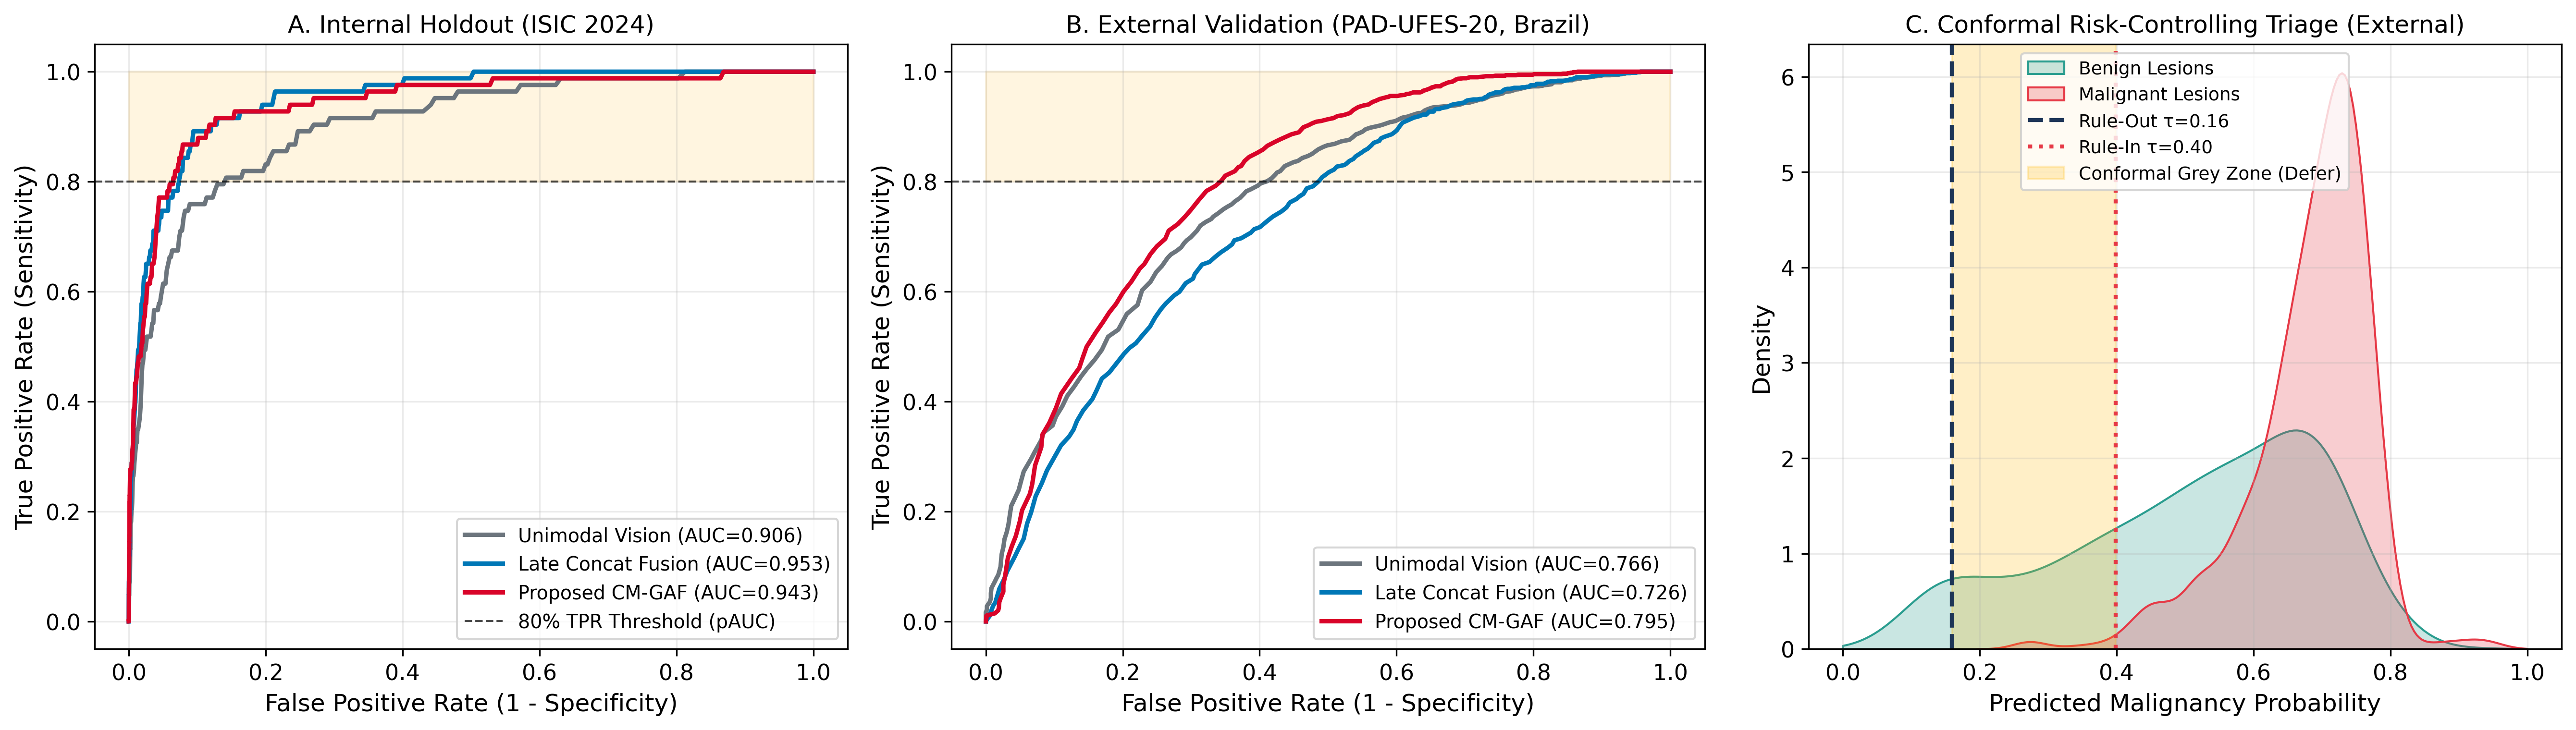

✅ Figuras exportadas en alta resolución (300 DPI):
 - /content/outputs_q1_paper/Figure1_Q1_Multimodal_Triage_Results.png
 - /content/outputs_q1_paper/Figure1_Q1_Multimodal_Triage_Results.pdf


In [13]:
# ==============================================================================
# CELDA 9: FIGURAS DE CALIDAD EDITORIAL (300 DPI) PARA EL MANUSCRITO Q1
# ==============================================================================
plt.rcParams.update({"font.size": 11, "axes.labelsize": 12, "axes.titlesize": 12})
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=300)

colors = {"image_only": "#6c757d", "late_concat": "#0077b6", "cm_gaf": "#d90429"}
labels_map = {
    "image_only": "Unimodal Vision",
    "late_concat": "Late Concat Fusion",
    "cm_gaf": "Proposed CM-GAF"
}

# Panel A: Internal Test ROC (ISIC 2024)
ax = axes[0]
for m_key in ["image_only", "late_concat", "cm_gaf"]:
    y_t = ablation_results[m_key]["y_id"]
    p_t = ablation_results[m_key]["p_id"]
    fpr, tpr, _ = roc_curve(y_t, p_t)
    auc_v = roc_auc_score(y_t, p_t)
    ax.plot(fpr, tpr, lw=2.2, color=colors[m_key], label=f"{labels_map[m_key]} (AUC={auc_v:.3f})")
ax.axhline(0.80, color="black", linestyle="--", lw=1.0, alpha=0.7, label="80% TPR Threshold (pAUC)")
ax.fill_between([0, 1], 0.80, 1.0, color="#ffd166", alpha=0.20)
ax.set_title("A. Internal Holdout (ISIC 2024)")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.legend(loc="lower right", frameon=True, fontsize=9.5)
ax.grid(alpha=0.25)

# Panel B: External Validation ROC (PAD-UFES-20 Brazil)
ax = axes[1]
for m_key in ["image_only", "late_concat", "cm_gaf"]:
    y_t = ablation_results[m_key]["y_ood"]
    p_t = ablation_results[m_key]["p_ood"]
    fpr, tpr, _ = roc_curve(y_t, p_t)
    auc_v = roc_auc_score(y_t, p_t)
    ax.plot(fpr, tpr, lw=2.2, color=colors[m_key], label=f"{labels_map[m_key]} (AUC={auc_v:.3f})")
ax.axhline(0.80, color="black", linestyle="--", lw=1.0, alpha=0.7)
ax.fill_between([0, 1], 0.80, 1.0, color="#ffd166", alpha=0.20)
ax.set_title("B. External Validation (PAD-UFES-20, Brazil)")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.legend(loc="lower right", frameon=True, fontsize=9.5)
ax.grid(alpha=0.25)

# Panel C: Conformal Triage Zones on External Cohort
ax = axes[2]
y_ood = res_cm["y_ood"]
p_ood = res_cm["p_ood"]
sns.kdeplot(p_ood[y_ood == 0], ax=ax, fill=True, color="#2a9d8f", label="Benign Lesions", clip=(0, 1))
sns.kdeplot(p_ood[y_ood == 1], ax=ax, fill=True, color="#e63946", label="Malignant Lesions", clip=(0, 1))
ax.axvline(tau_out, color="#1d3557", linestyle="--", lw=2.0, label=f"Rule-Out τ={tau_out:.2f}")
ax.axvline(tau_in, color="#e63946", linestyle=":", lw=2.0, label=f"Rule-In τ={tau_in:.2f}")
ax.axvspan(tau_out, tau_in, color="#ffb703", alpha=0.22, label="Conformal Grey Zone (Defer)")
ax.set_title("C. Conformal Risk-Controlling Triage (External)")
ax.set_xlabel("Predicted Malignancy Probability")
ax.set_ylabel("Density")
ax.legend(loc="upper center", frameon=True, fontsize=9)
ax.grid(alpha=0.25)

plt.tight_layout()
fig_path_png = OUTPUT_DIR / "Figure1_Q1_Multimodal_Triage_Results.png"
fig_path_pdf = OUTPUT_DIR / "Figure1_Q1_Multimodal_Triage_Results.pdf"
plt.savefig(fig_path_png, dpi=300, bbox_inches="tight")
plt.savefig(fig_path_pdf, bbox_inches="tight")
plt.show()
print(f"✅ Figuras exportadas en alta resolución (300 DPI):\n - {fig_path_png}\n - {fig_path_pdf}")
